In [2]:
suppressMessages(library(ArchR))
suppressMessages(library(Seurat))
suppressMessages(library(Signac))
suppressMessages(library(scMEGA))
suppressMessages(library(harmony))
suppressMessages(library(Nebulosa))
suppressMessages(library(ggplot2))
suppressMessages(library(dplyr))
# suppressMessages(library(JASPAR2020))
suppressMessages(library(TFBSTools))
suppressMessages(library(igraph))
suppressMessages(library(ggraph))
suppressMessages(library(qs))
# suppressMessages(library(BSgenome.Hsapiens.UCSC.hg38))

plan("multicore", workers = 128)
options(future.globals.maxSize = 100000 * 1024^5)

In [2]:
suppressMessages(library(reticulate))
RETICULATE_PYTHON <- "/home/chaiqw/project/betz_anal_new/.venv/bin/python"
use_virtualenv("/home/chaiqw/project/betz_anal_new/.venv")

In [ ]:
rna = qread('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/from_zzy_transfer/snRNA-data/keep3Animal_kepler_Anot_Betz.qs')
sub_rna = subset(rna, subclass == 'L5-ET(PT)' )


In [ ]:
obj <- qs::qread("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/from_zzy_transfer/snRNA-data/L5-ET_PT__mega-rna_.qs")

old_prefix <- "/sdd/bgi/zhuzhiyong/motor_cortex/source_data/sn_cre"
new_prefix <- "/mnt/112-rawdata-112/macaque/snRNA/motor_cortex/sn_cre"

chrom_assays <- Filter(function(a) inherits(obj[[a]], "ChromatinAssay"), Assays(obj))

for (assay in chrom_assays) {
  frags <- Fragments(obj, assay = assay)
  for (i in seq_along(frags)) {
    old_path <- frags[[i]]@path
    # 仅当路径以旧前缀开头时替换
    if (startsWith(old_path, old_prefix)) {
      new_path <- sub(old_prefix, new_prefix, old_path, fixed = TRUE)
      # 只更新路径，不重建 Fragment 对象
      frags[[i]]@path <- new_path
    }
  }
  obj[[assay]]@fragments <- frags
}

In [6]:
obj.rna = sub_rna
obj.atac = obj 
gene.activity = obj@assays$GeneActivity$data


Normalizing layer: counts



Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
Warning message:
“Number of dimensions changing from 50 to 20”
Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
01:09:17 UMAP embedding parameters a = 0.9922 b = 1.112

01:09:17 Read 3713 rows and found 5 numeric columns

01:09:17 Using Annoy for neighbor search, n_neighbors = 30

01:09:17 Building Annoy index with metric = cosi

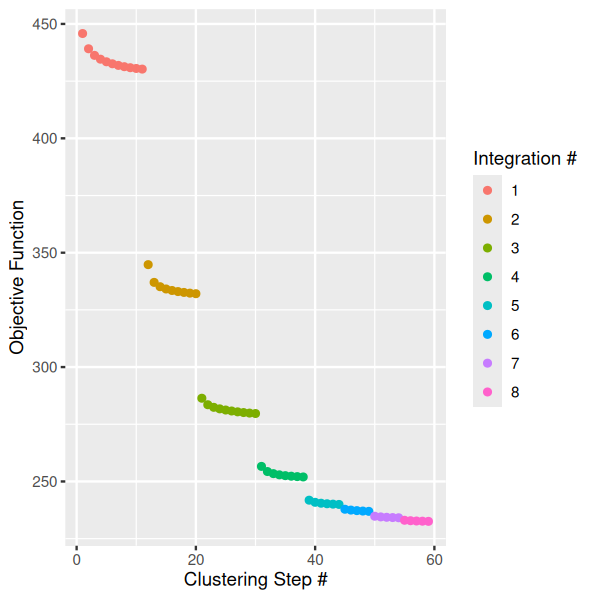

In [103]:
# M1_data_sub_1 = JoinLayers(sub_rna)
M1_data_sub_1 <- obj.rna %>% 
    NormalizeData(normalization.method = "LogNormalize") %>% 
    FindVariableFeatures( nfeatures = 10000) %>% 
    ScaleData() %>% 
    # SCTransform(variable.features.n = 2000) %>% 
    RunPCA(npcs=20,verbose = FALSE) 

M1_data_sub_2 <- M1_data_sub_1 %>% 
    FindNeighbors(dims = 1:5) %>%
    FindClusters(verbose = FALSE, resolution = 0.5, random.seed = 1234) %>%
    RunUMAP(dims = 1:5, seed.use = 1234)

M1_data_sub_3 = RunHarmony(
    M1_data_sub_2, group.by.vars=c("Animal"), plot_convergence=T,
    reduction.save = "harmony", dims.use=1:5,
    theta=2)

M1_data_sub_4 <- M1_data_sub_3 %>%
    FindNeighbors(reduction="harmony", dims = 1:5,k.param = 50) %>%
    FindClusters(verbose = FALSE,resolution = 0.4, random.seed = 666) %>%
    RunUMAP(reduction="harmony", dims = 1:5,min.dist = 0.5)


In [104]:
ref.rna = M1_data_sub_4
ref.atac = obj.atac

In [105]:
ref.rna$celltype_new <- as.character(ref.rna$celltype)
ref.rna$celltype_new[ref.rna$celltype_new %in% c("L5-ET(PT).02(Betz-Like)", "L5-ET(PT).00")] <- "betz"
ref.rna$celltype_new[!(ref.rna$celltype_new %in% c("betz")) & grepl("L5-ET", ref.rna$celltype_new)] <- "other L5 ET"
ref.rna$celltype_new <- as.factor(ref.rna$celltype_new)

In [106]:

transfer.anchors <- FindTransferAnchors(reference = ref.rna, query = ref.atac, features = VariableFeatures(object = ref.rna), 
                                        reference.assay = "RNA", query.assay = "GeneActivity", reduction = "cca")
celltype.predictions <- TransferData(
    anchorset = transfer.anchors,
    refdata = ref.rna$celltype_new, 
    weight.reduction = ref.atac[["lsi"]],
    dims = 1:5
)
ref.atac <- AddMetaData(ref.atac, metadata = celltype.predictions)

Warning message:
“218 features of the features specified were not present in both the reference query assays. 
Continuing with remaining 9782 features.”


Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 4508 anchors

Finding integration vectors

Finding integration vector weights

Predicting cell labels



In [ ]:
genes.use <- VariableFeatures(ref.rna)
refdata <- GetAssayData(ref.rna, assay = "RNA", layer = "data")[genes.use, ]

imputation <- TransferData(anchorset = transfer.anchors, refdata = refdata, weight.reduction = ref.atac[["lsi"]],dims = 1:5)

ref.atac[["RNA"]] <- imputation

ref.rna$tech = 'RNA'
ref.atac$tech = 'ATAC'
coembed <- merge(x = ref.rna, y = ref.atac)

coembed <- ScaleData(coembed, features = genes.use, do.scale = FALSE)
coembed <- RunPCA(coembed, features = genes.use, verbose = FALSE)
coembed <- RunHarmony(coembed, group.by.vars = "Animal", reduction.save = "harmony", dims.use = 1:5)
coembed <- FindNeighbors(coembed, dims = 1:5, reduction = "harmony")
coembed <- FindClusters(coembed, resolution = 0.2, random.seed = 1234,reduction = "harmony")
coembed <- RunUMAP(coembed, dims = 1:5, reduction = "harmony")


Warning message:
“The following arguments are not used: reduction”


Warning message:
“The following arguments are not used: reduction”


Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4641
Number of edges: 135225

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8994
Number of communities: 3
Elapsed time: 0 seconds


Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
16:56:22 UMAP embedding parameters a = 0.9922 b = 1.112

16:56:22 Read 4641 rows and found 5 numeric columns

16:56:22 Using Annoy for neighbor search, n_neighbors = 30

16:56:22 Building Annoy index with metric = 

In [22]:
coembed$celltype_new <- ifelse(!is.na(coembed$celltype_new), coembed$celltype_new, coembed$predicted.id)

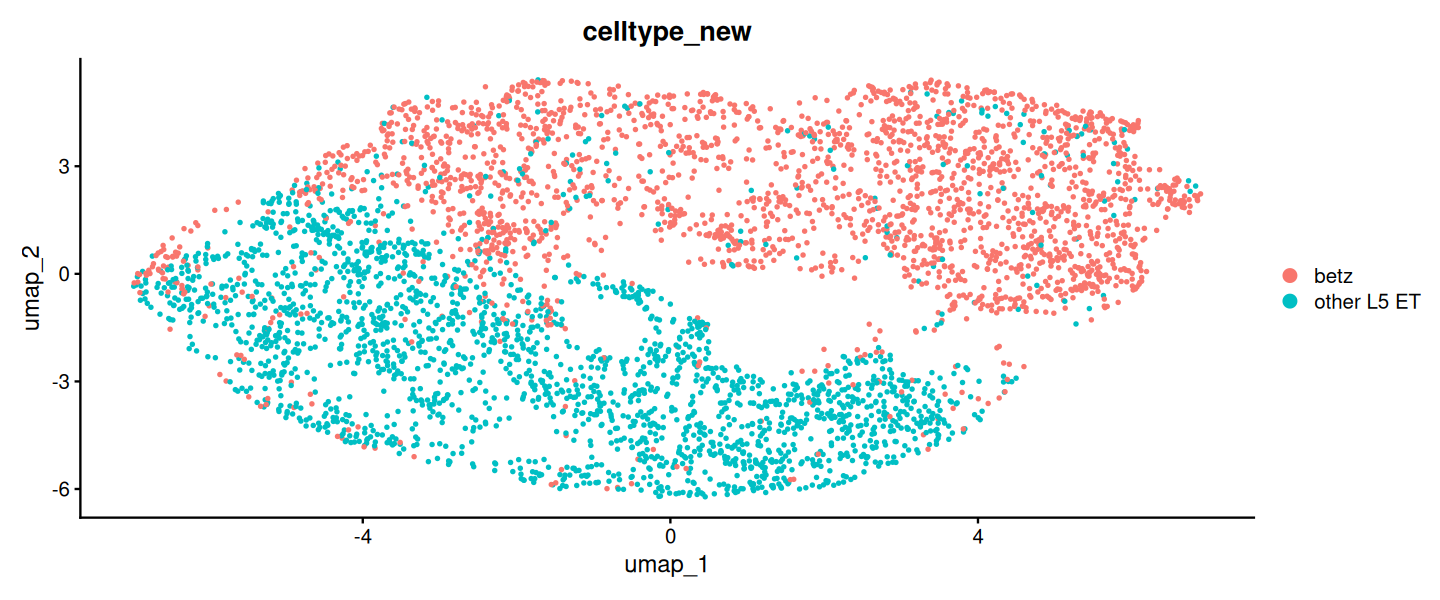

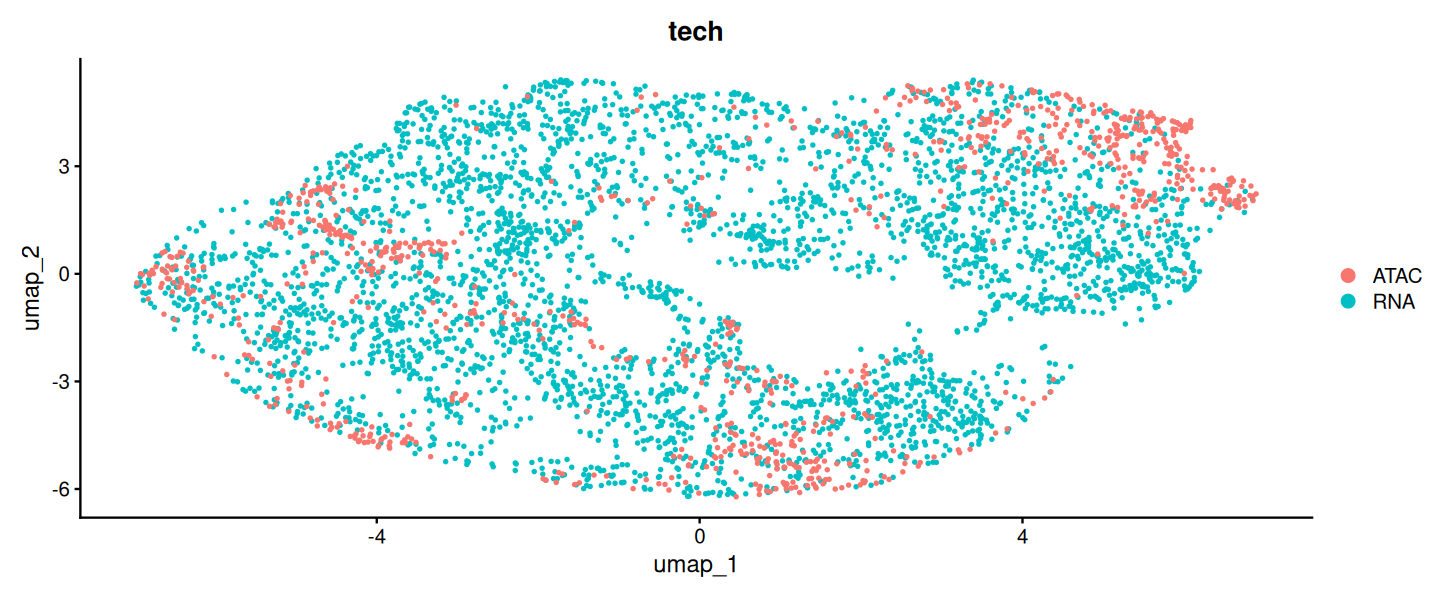

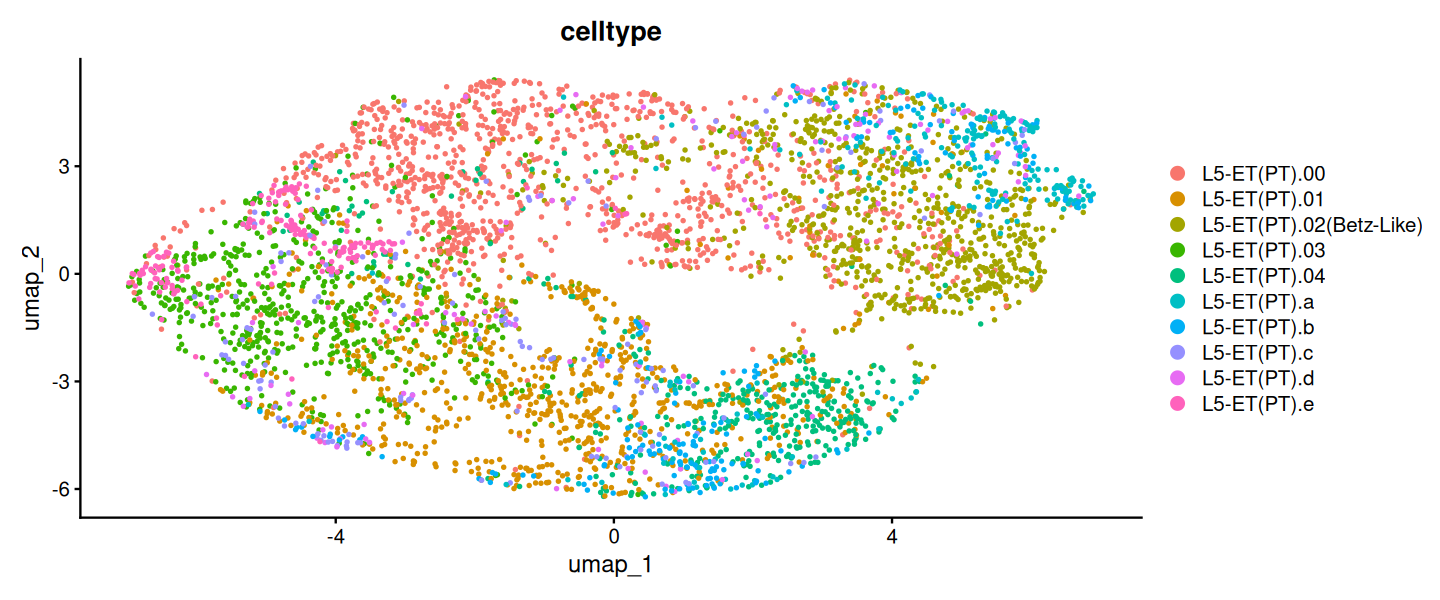

In [12]:
DimPlot(coembed, group.by = "celltype_new")
DimPlot(coembed, group.by = "tech")

DimPlot(coembed, group.by = "celltype")

In [29]:
options(repr.plot.width = 11, repr.plot.height = 5)
Idents(coembed) <- 'celltype_betz'
pdf("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251216_RNA_ATAC_splitbytech_celltype_betz.pdf", width = 11, height = 5)
DimPlot(
  coembed,
  split.by = "tech",
  cols = c("#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e", "#17becf", "#e377c2", "#7f7f7f", "#bcbd22", "#8c564b")
)
dev.off()


agg_record_27662504 
                  2

In [24]:
# 合并 L5-ET(PT).02(Betz-Like) 和 L5-ET(PT).00 为 celltype_new
coembed$celltype_betz <- as.character(coembed$celltype)
coembed$celltype_betz[coembed$celltype_betz %in% c("L5-ET(PT).02(Betz-Like)", "L5-ET(PT).00")] <- "Betz Like Cluster"
coembed$celltype_betz <- as.factor(coembed$celltype_betz)

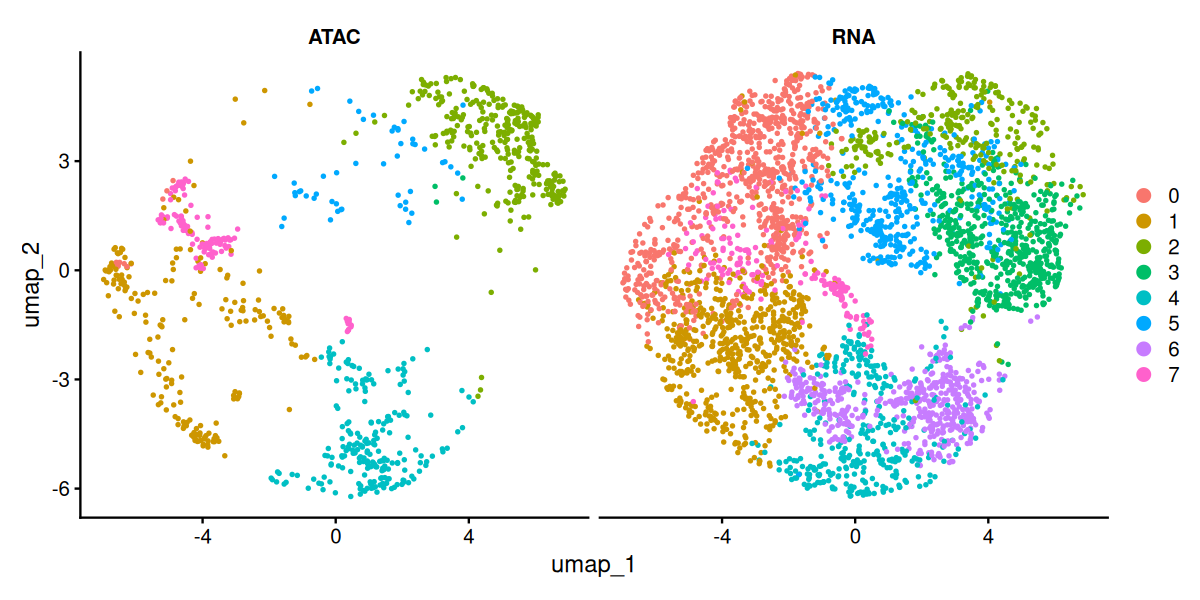

In [8]:
options(repr.plot.width = 10, repr.plot.height = 5)
Idents(coembed) <- 'seurat_clusters'
DimPlot(
  coembed,
  split.by = "tech"
)

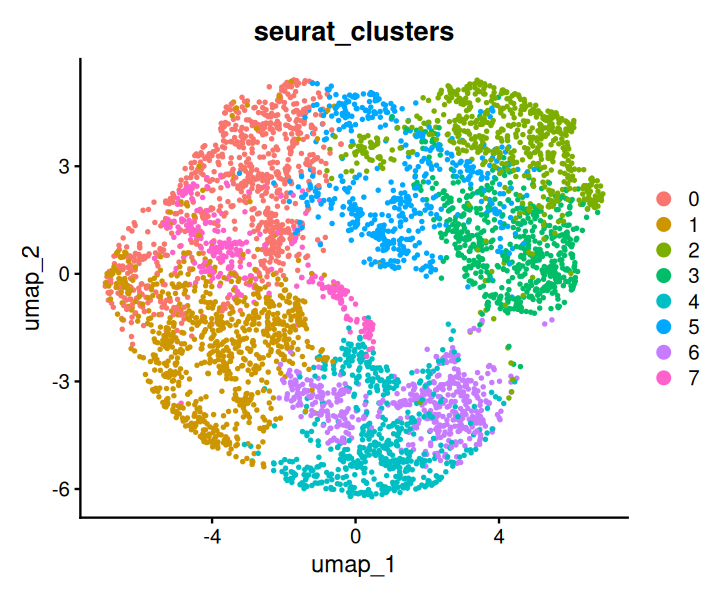

In [7]:
options(repr.plot.width = 6, repr.plot.height = 5)
Idents(coembed) <- 'seurat_clusters'
DimPlot(
  coembed,
  group.by = "seurat_clusters"
)

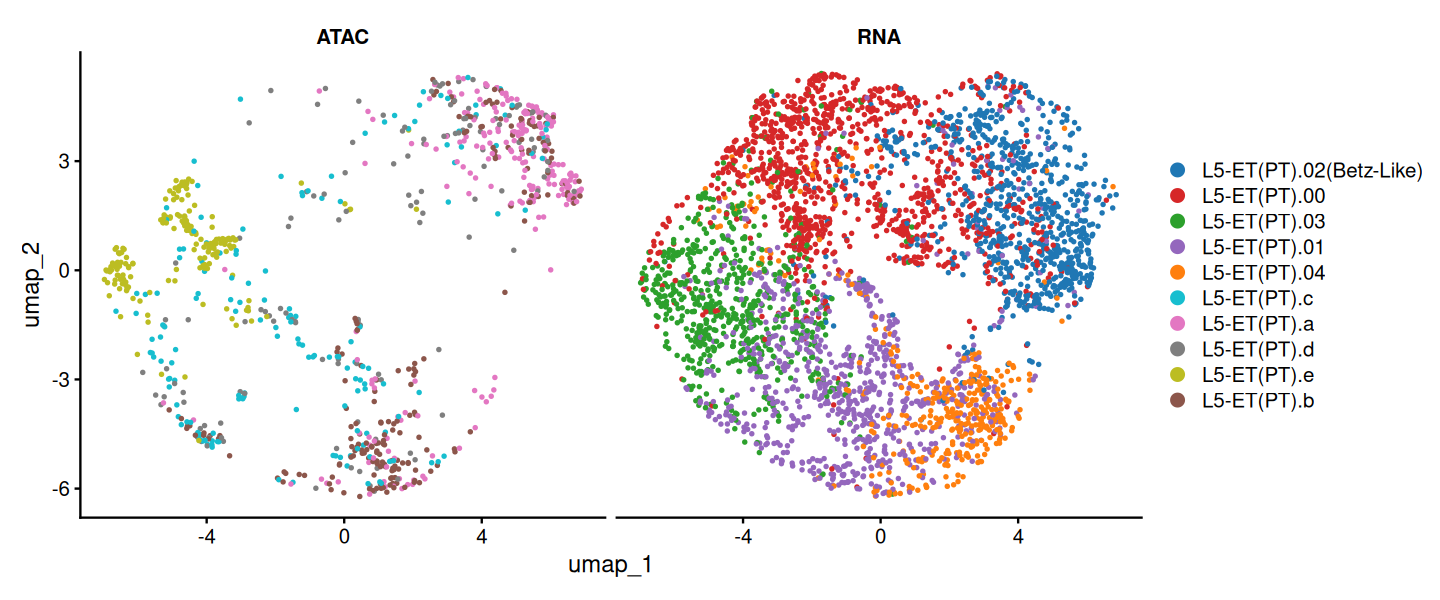

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 5)
Idents(coembed) <- 'celltype'
DimPlot(
  coembed,
  split.by = "tech",
  cols = c("#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e", "#17becf", "#e377c2", "#7f7f7f", "#bcbd22", "#8c564b")
)

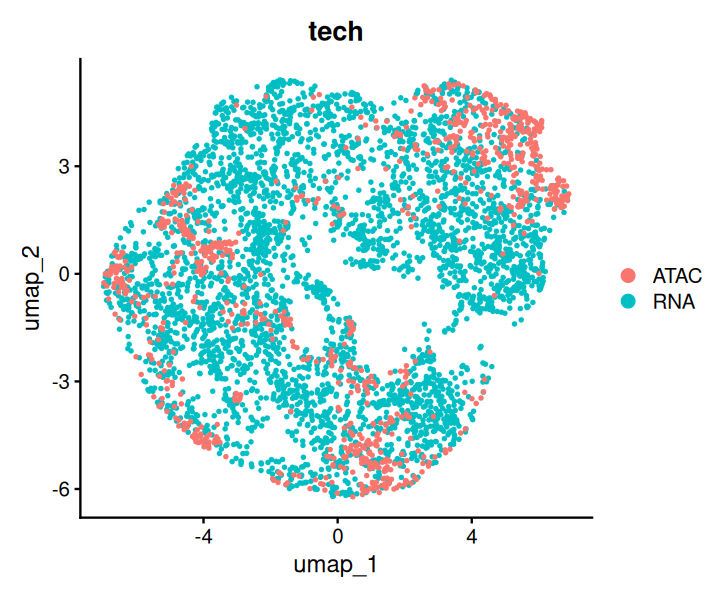

In [6]:
options(repr.plot.width = 6, repr.plot.height = 5)
Idents(coembed) <- 'seurat_clusters'
DimPlot(
  coembed,
  group.by = "tech"
)

Warning message:
“Scaling data with a low number of groups may produce misleading results”


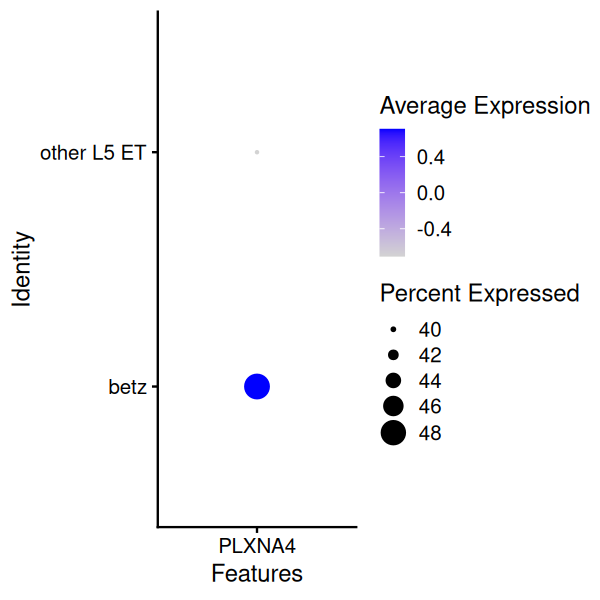

In [176]:
options(repr.plot.width = 5, repr.plot.height = 5)
Idents(coembed) <- 'celltype_new'
DotPlot(coembed, features = "PLXNA4")

In [171]:
saveRDS(coembed, file = "coembed_5000feature-new05.rds")

In [17]:
coembed = readRDS("coembed_5000feature-new05.rds")